In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('Final_Project_dataset.csv')
# 1. عرض أبعاد البيانات والمعلومات الأساسية
print("أبعاد ملف البيانات (Shape)")
print(df.shape)

print("\n أسماء الأعمدة وأنواع البيانات ")
print(df.info())

print("\n المعاينة الأولى للبيانات (First 5 Rows) ")
display(df.head())

أبعاد ملف البيانات (Shape)
(3900, 19)

 أسماء الأعمدة وأنواع البيانات 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   objec

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
print("عدد القيم المفقودة لكل عمود")
print(df.isnull().sum())

# 2. فحص الصفوف المكررة (Duplicates)
print("\n عدد الصفوف المكررة")
print(df.duplicated().sum())

عدد القيم المفقودة لكل عمود
Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

 عدد الصفوف المكررة
0


In [5]:
print("Age range:",
      df["Age"].min(), "-", df["Age"].max())

print("Purchase amount range:",
      df["Purchase Amount (USD)"].min(), "-",
      df["Purchase Amount (USD)"].max())

print("Review rating range:",
      df["Review Rating"].min(), "-",
      df["Review Rating"].max())

Age range: 18 - 70
Purchase amount range: 20 - 100
Review rating range: 2.5 - 5.0


In [6]:
amount = df["Purchase Amount (USD)"]

print("Total purchase amount:", amount.sum())
print("Average purchase amount:", round(amount.mean(),2))
print("Minimum purchase amount:", amount.min())
print("Maximum purchase amount:", amount.max())
print("Median purchase amount:", amount.median())

print("Standard deviation:", amount.std())
display(amount.describe())

Total purchase amount: 233081
Average purchase amount: 59.76
Minimum purchase amount: 20
Maximum purchase amount: 100
Median purchase amount: 60.0
Standard deviation: 23.685392250875307


,Purchase Amount (USD)
count,3900.000000
mean,59.764359
std,23.685392
min,20.000000
25%,39.000000
50%,60.000000
75%,81.000000
max,100.000000


In [7]:
category_analysis = (
    df.groupby("Category")["Purchase Amount (USD)"]
      .agg(["count", "sum", "mean"])
      .sort_values("sum", ascending=False))
display(category_analysis.round(2))

,count,sum,mean
Category,,,
Clothing,1737,104264,60.03
Accessories,1240,74200,59.84
Footwear,599,36093,60.26
Outerwear,324,18524,57.17


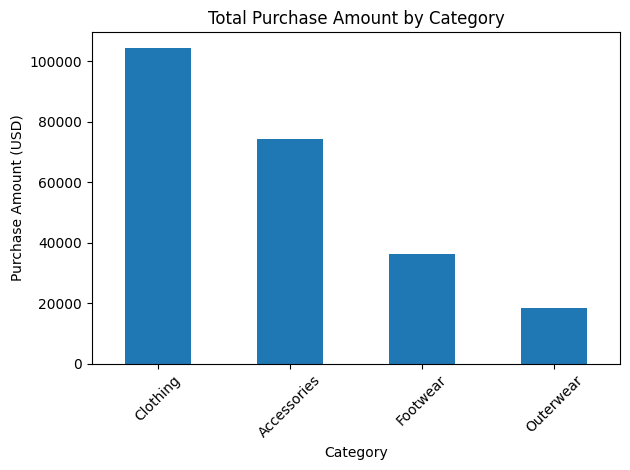

In [8]:
category_analysis["sum"].plot(
    kind="bar",
    title="Total Purchase Amount by Category",
    ylabel="Purchase Amount (USD)"
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
season_analysis = (
    df.groupby("Season")["Purchase Amount (USD)"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

display(season_analysis)

,count,sum,mean
Season,,,
Fall,975,60018,61.556923
Winter,971,58607,60.357364
Spring,999,58679,58.737738
Summer,955,55777,58.405236


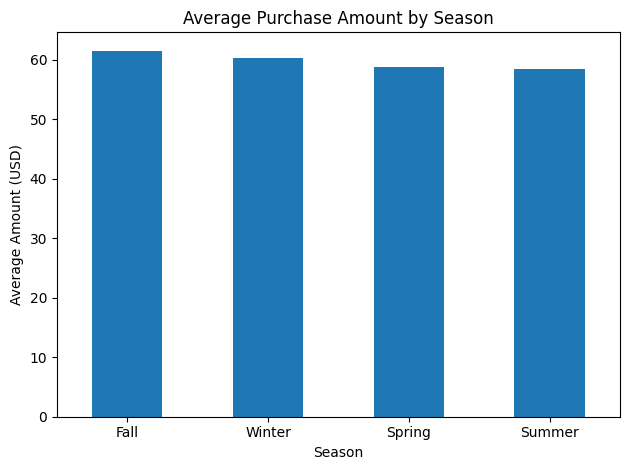

In [11]:
season_analysis["mean"].plot(
    kind="bar",
    title="Average Purchase Amount by Season",
    ylabel="Average Amount (USD)"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
category_season = pd.pivot_table(
    df,
    index="Category",
    columns="Season",
    values="Purchase Amount (USD)",
    aggfunc="mean"
)

display(category_season.round(2))

Season,Fall,Spring,Summer,Winter
Category,,,,
Accessories,61.34,56.50,60.99,60.37
Clothing,61.41,61.00,56.56,60.88
Footwear,63.71,58.62,58.71,60.57
Outerwear,59.76,54.63,57.04,57.02


In [13]:
payment_analysis = (
    df.groupby("Payment Method")["Purchase Amount (USD)"]
      .agg(["count", "sum", "mean"])
      .sort_values("count", ascending=False)
)

display(payment_analysis.round(2))

,count,sum,mean
Payment Method,,,
Credit Card,696,42567,61.16
Venmo,653,39991,61.24
Cash,648,38833,59.93
PayPal,638,37449,58.70
Debit Card,633,37118,58.64
Bank Transfer,632,37123,58.74


In [14]:
discount_analysis = (
    df.groupby("Discount Applied")["Purchase Amount (USD)"]
      .agg(["count", "sum","mean"])
)

display(discount_analysis.round(2))


,count,sum,mean
Discount Applied,,,
No,2223,133670,60.13
Yes,1677,99411,59.28
